In [1]:
import hashlib
import random
from collections import OrderedDict

import numpy as np
import pennylane as qp
import torch
import torch.nn as nn
from matplotlib import pyplot as plt

from qiskit import QuantumCircuit, transpile
from qiskit.circuit import Parameter, ParameterVector
from qiskit.circuit.library import RZGate, SXGate, SXdgGate, XGate
from qiskit.primitives import BackendEstimatorV2, BaseEstimatorV2
from qiskit.primitives.containers import PrimitiveResult, PubResult
from qiskit.primitives.containers.estimator_pub import EstimatorPub
from qiskit.providers import JobStatus
from qiskit.quantum_info import SparsePauliOp

from qiskit_aer import AerSimulator

from qiskit_algorithms.gradients import ReverseEstimatorGradient

from qiskit_ibm_runtime import EstimatorV2, QiskitRuntimeService, Session
from qiskit_ibm_runtime.options import EstimatorOptions

from qiskit_machine_learning.connectors import TorchConnector
from qiskit_machine_learning.neural_networks import EstimatorQNN

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

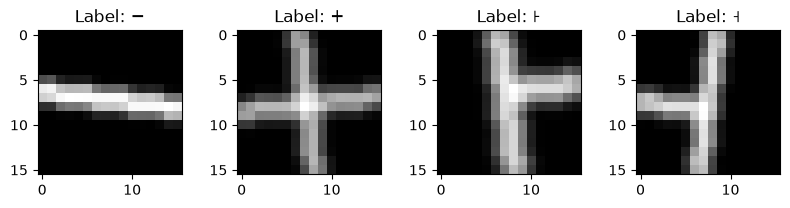

In [ ]:
# loading dataset
[pm] = qp.data.load("other", name="plus-minus")

X_train = pm.img_train  # shape (1000,16,16)
X_test = pm.img_test  # shape (200,16,16)
Y_train = pm.labels_train  # shape (1000,)
Y_test = pm.labels_test  # shape (200,)

x_vis = [
    (X_train[Y_train == 0])[0],
    (X_train[Y_train == 1])[0],
    (X_train[Y_train == 2])[0],
    (X_train[Y_train == 3])[0],
]
y_vis = [0, 1, 2, 3]


def visualize_data(x, y, pred=None):
    """Plot a row of up to four 16x16 grayscale digit images with their labels.

    Parameters
    ----------
    x : Sequence[np.ndarray]
        Images to display, each of shape (16, 16).
    y : Sequence[int]
        Ground-truth class index (0-3) for each image in ``x``.
    pred : Sequence[int] or None, optional
        Predicted class index for each image. When provided, the subplot
        titles show both the true label and the prediction; otherwise only
        the true label is shown.

    Returns
    -------
    None
        The figure is rendered directly with ``plt.show()``.
    """
    n_img = len(x)
    labels_list = ["\u2212", "\u002b", "\ua714", "\u02e7"]
    fig, axes = plt.subplots(1, 4, figsize=(8, 2))
    for i in range(n_img):
        axes[i].imshow(x[i], cmap="gray")
        if pred is None:
            axes[i].set_title("Label: {}".format(labels_list[y[i]]))
        else:
            axes[i].set_title(
                "Label: {}, Pred: {}".format(labels_list[y[i]], labels_list[pred[i]])
            )
    plt.tight_layout(w_pad=2)
    plt.show()


visualize_data(x_vis, y_vis)

In [ ]:

class QiskitReuploadingClassifier(nn.Module):
    """Hybrid classical-quantum image classifier (PyTorch module).

    Wraps a parameterized Qiskit circuit (a "strongly entangling" ansatz,
    mirroring PennyLane's template of the same name) as a differentiable
    PyTorch layer. A classical linear layer projects the flattened input
    image onto a full vector of rotation angles in a single pass; those
    angles are then affine-transformed by learnable per-angle weight/bias
    parameters before being bound into the quantum circuit. The circuit is
    evaluated as a set of per-qubit Z expectation values, one per output
    class, via Qiskit Machine Learning's ``EstimatorQNN``/``TorchConnector``.

    Naming note: despite the class name and the "data re-uploading" framing
    used in earlier versions, the classical input is only
    embedded once per forward pass. The raw input is
    never re-encoded at later layers, so this differs from data
    re-uploading in the technical sense.
     Architecturally, this a single classical-to-quantum
    embedding feeding a multi-layer strongly-entangling ansatz.

    Attributes
    ----------
    num_qubits : int
        Number of qubits in the circuit (and columns of the input image
        after flattening are projected onto ``num_layers * num_qubits * 3``
        rotation angles).
    output_dim : int
        Number of output classes; also the number of qubits whose Z
        expectation value is read out.
    num_layers : int
        Number of entangling layers in the ansatz.
    total_angles : int
        Total number of rotation angles (``num_layers * num_qubits * 3``).
    input_projection : torch.nn.Linear
        Learnable linear map from the flattened input to ``total_angles``
        raw rotation angles.
    weights, bias : torch.nn.Parameter
        Learnable per-angle scale and shift applied to the projected angles
        before they are bound into the quantum circuit.
    logical_qc : qiskit.QuantumCircuit
        The un-transpiled ("logical") parameterized circuit.
    params : qiskit.circuit.ParameterVector
        Symbolic parameters of the logical circuit.
    qc : qiskit.QuantumCircuit
        The circuit actually executed; equal to ``logical_qc`` unless a
        ``backend`` is supplied, in which case it is the transpiled,
        hardware-native version.
    logical_observables, observables : list[SparsePauliOp]
        Per-class single-qubit Z observables, expressed on the logical and
        (if transpiled) physical qubit layout respectively.
    qcircuit : qiskit_machine_learning.connectors.TorchConnector
        The differentiable PyTorch layer wrapping the ``EstimatorQNN``.

    Parameters
    ----------
    input_dim : int, default 256
        Size of the flattened input (e.g. 16x16 images -> 256).
    output_dim : int, default 4
        Number of output classes.
    num_qubits : int, default 8
        Number of qubits used by the ansatz.
    num_layers : int, default 2
        Number of entangling layers.
    estimator : qiskit.primitives.BaseEstimatorV2 or None
        Estimator primitive used to evaluate expectation values (e.g. an
        exact statevector estimator, a noisy density-matrix simulator, or
        an error-mitigated wrapper around real hardware).
    backend : qiskit.providers.BackendV2 or None
        If given, the logical circuit is transpiled to this backend's
        native gate set/connectivity before execution, and the observables
        are re-mapped onto the resulting physical qubit layout.
    """

    def __init__(
        self,
        input_dim=256,
        output_dim=4,
        num_qubits=8,
        num_layers=2,
        num_reup=3,
        estimator=None,
        backend=None,
    ):
        """See class docstring for parameter and attribute details."""
        super().__init__()
        self.num_qubits = num_qubits
        self.output_dim = output_dim
        self.num_layers = num_layers
        self.num_reup = num_reup

        # 3 rotations per qubit per layer
        self.total_angles = num_layers * num_qubits * 3
        self.input_projection = nn.Linear(input_dim, self.total_angles)

        self.weights = nn.Parameter(0.1 * torch.rand(self.total_angles))
        self.bias = nn.Parameter(0.1 * torch.rand(self.total_angles))

        self.qc, self.params = self._build_strongly_entangling_circuit()
        if backend is not None:
            self.qc = transpile(
                self.qc,
                backend=backend,
                optimization_level=0,
                seed_transpiler=42,
            )

        self.params = list(self.qc.parameters)

        self.observables = [
            SparsePauliOp.from_sparse_list(
                [("Z", [i], 1)],
                num_qubits=self.num_qubits,
            )
            for i in range(self.output_dim)
        ]

        if backend is not None and self.qc.layout is not None:
            self.observables = [
                obs.apply_layout(self.qc.layout) for obs in self.observables
            ]
        print(self.qc.num_qubits)
        print(self.qc.num_parameters)
        qnn = EstimatorQNN(
            circuit=self.qc,
            observables=self.observables,
            input_params=self.params,
            weight_params=[],
            estimator=estimator,
            input_gradients=True,
            gradient=ReverseEstimatorGradient(),
        )

        self.qcircuit = TorchConnector(qnn)

    # the same implementation as strongly entangling circuit function from pennylane
    def _build_strongly_entangling_circuit(self):
        """Construct the strongly-entangling variational ansatz.

        Builds a circuit with ``num_layers`` repetitions of: a per-qubit
        RZ-RY-RZ rotation block (consuming three fresh parameters per
        qubit) followed by a ring of CNOTs whose "stride" cycles with the
        layer index, mirroring PennyLane's ``StronglyEntanglingLayers``
        template.

        Returns
        -------
        tuple[qiskit.QuantumCircuit, qiskit.circuit.ParameterVector]
            The parameterized circuit and the vector of symbolic rotation
            parameters bound into it.
        """
        qc = QuantumCircuit(self.num_qubits)
        params = ParameterVector("θ", self.total_angles)

        idx = 0
        for layer in range(self.num_layers):
            for q in range(self.num_qubits):
                qc.rz(params[idx], q)
                qc.ry(params[idx + 1], q)
                qc.rz(params[idx + 2], q)
                idx += 3

            step = (layer % (self.num_qubits - 1)) + 1
            for q in range(self.num_qubits):
                target = (q + step) % self.num_qubits
                qc.cx(q, target)

        return qc, params

    def forward(self, x):
        """Run a batch of inputs through the classifier.

        Parameters
        ----------
        x : torch.Tensor
            Batch of flattened input features, shape ``(batch, input_dim)``.

        Returns
        -------
        torch.Tensor
            Per-class expectation values, shape ``(batch, output_dim)``,
            usable directly as logits for ``nn.CrossEntropyLoss``.
        """
        angles = self.input_projection(x)
        angles = self.weights * angles + self.bias
        return self.qcircuit(angles)


device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

model = QiskitReuploadingClassifier().to(device)

dummy_data = torch.rand(5, 256).to(device)
output = model(dummy_data)

print("Output shape:", output.shape)  # Expected: [5, 4]

Using device: cpu
8
48
Output shape: torch.Size([5, 4])


In [5]:
# instantiating the model
input_dim = 256
num_classes = 4
num_qubits = 8
num_layers = 2

qml_model = QiskitReuploadingClassifier(
    input_dim=input_dim,
    output_dim=num_classes,
    num_qubits=num_qubits,
    num_layers=num_layers,
).to(device)

8
48


In [6]:
# Hyperparameters
learning_rate = 0.05
epochs = 3
batch_size = 20
input_dim = 256
num_classes = 4
num_qubits = 8
num_layers = 2

feats_train = torch.from_numpy(X_train[:200]).reshape(200, -1).float().to(device)
feats_test = torch.from_numpy(X_test[:50]).reshape(50, -1).float().to(device)
labels_train = torch.from_numpy(Y_train[:200]).long().to(device)
labels_test = torch.from_numpy(Y_test[:50]).long().to(device)
num_train = feats_train.shape[0]

qml_model = QiskitReuploadingClassifier(
    input_dim=input_dim,
    output_dim=num_classes,
    num_qubits=num_qubits,
    num_layers=num_layers,
).to(device)


loss = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(qml_model.parameters(), lr=learning_rate)
num_batches = num_train // batch_size


def accuracy(labels, predictions):
    """Compute classification accuracy from raw model outputs.

    Parameters
    ----------
    labels : torch.Tensor
        Ground-truth integer class labels, shape ``(batch,)``.
    predictions : torch.Tensor
        Model outputs/logits, shape ``(batch, num_classes)``.

    Returns
    -------
    float
        Fraction of samples where ``argmax(predictions)`` matches ``labels``.
    """
    predicted_classes = torch.argmax(predictions, dim=1)
    correct = (predicted_classes == labels).sum().item()
    return correct / len(labels)


def gen_batches(num_samples, num_batches):
    """Generate a random, non-overlapping partition of sample indices.

    Parameters
    ----------
    num_samples : int
        Total number of training samples to partition.
    num_batches : int
        Number of equally sized batches to split them into. Must evenly
        divide ``num_samples``.

    Returns
    -------
    torch.Tensor
        Integer tensor of shape ``(num_batches, num_samples // num_batches)``
        containing a random permutation of ``range(num_samples)`` reshaped
        into batches.

    Raises
    ------
    AssertionError
        If ``num_samples`` is not evenly divisible by ``num_batches``.
    """
    assert num_samples % num_batches == 0
    perm_ind = torch.reshape(torch.randperm(num_samples), (num_batches, -1))
    return perm_ind


def print_acc(epoch, max_ep=4):
    """Print training/validation loss and accuracy for the current epoch.

    Evaluates ``qml_model`` (module-level global) in ``no_grad`` mode on a
    50-sample slice of the training set and the full test set, then prints
    a formatted summary line. Uses the module-level ``loss`` criterion and
    ``feats_train``/``labels_train``/``feats_test``/``labels_test`` tensors.

    Parameters
    ----------
    epoch : int
        Current epoch number, used only for the printed message.
    max_ep : int, default 4
        Total number of epochs, used only for the printed message.

    Returns
    -------
    None
    """
    with torch.no_grad():
        predictions_train = qml_model(feats_train[:50])
        predictions_test = qml_model(feats_test)

        cost_approx_train = loss(predictions_train, labels_train[:50])
        cost_approx_test = loss(predictions_test, labels_test)

        acc_approx_train = accuracy(labels_train[:50], predictions_train)
        acc_approx_test = accuracy(labels_test, predictions_test)

    print(
        f"Epoch {epoch}/{max_ep} | Approx Cost (train): {cost_approx_train:0.7f} | Cost (val): {cost_approx_test:0.7f} |"
        f" Approx Acc train: {acc_approx_train:0.7f} | Acc val: {acc_approx_test:0.7f}"
    )

8
48


Starting training loop for Qiskit variational classifier (8 qubits, 2 layers)...
Epoch 0/3 | Approx Cost (train): 1.3864183 | Cost (val): 1.3856709 | Approx Acc train: 0.2000000 | Acc val: 0.2800000
Epoch 1/3 | Approx Cost (train): 0.8457485 | Cost (val): 0.8512890 | Approx Acc train: 0.9600000 | Acc val: 0.9800000
Epoch 2/3 | Approx Cost (train): 0.7214705 | Cost (val): 0.7075105 | Approx Acc train: 0.9600000 | Acc val: 0.9800000
Epoch 3/3 | Approx Cost (train): 0.6815174 | Cost (val): 0.6905354 | Approx Acc train: 0.9200000 | Acc val: 0.9800000


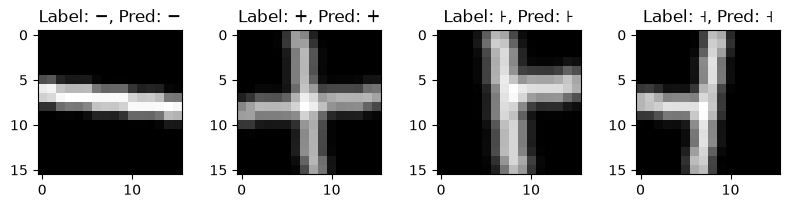

In [6]:
print(
    f"Starting training loop for Qiskit variational classifier ({num_qubits} qubits, {num_layers} layers)..."
)

for ep in range(epochs):
    batch_ind = gen_batches(num_train, num_batches)
    print_acc(epoch=ep, max_ep=epochs)

    for it in range(num_batches):
        optimizer.zero_grad()

        feats_train_batch = feats_train[batch_ind[it]]
        labels_train_batch = labels_train[batch_ind[it]]
        outputs = qml_model(feats_train_batch)
        batch_loss = loss(outputs, labels_train_batch)
        batch_loss.backward()
        optimizer.step()

print_acc(epochs, max_ep=epochs)

x_vis_torch = torch.from_numpy(np.array(x_vis).reshape(4, -1)).float().to(device)
y_vis_torch = torch.from_numpy(np.array(y_vis)).long().to(device)

with torch.no_grad():
    benign_preds = qml_model(x_vis_torch)

benign_class_output = torch.argmax(benign_preds, dim=1).cpu().numpy()
visualize_data(x_vis, y_vis, benign_class_output)

In [7]:
save_path = "qiskit_reuploading_classifier.pth"
torch.save(
    {
        "model_state_dict": qml_model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "epoch": epochs,
        "learning_rate": learning_rate,
    },
    save_path,
)
print(f"Model weights saved to {save_path}")

Model weights saved to qiskit_reuploading_classifier.pth


In [7]:
# if training is skipped
checkpoint = torch.load("qiskit_reuploading_classifier.pth", map_location=device)

qml_model.load_state_dict(checkpoint["model_state_dict"])
optimizer.load_state_dict(checkpoint["optimizer_state_dict"])
start_epoch = checkpoint["epoch"]

feats_train = torch.from_numpy(X_train[:200]).reshape(200, -1).float().to(device)
feats_test = torch.from_numpy(X_test[:50]).reshape(50, -1).float().to(device)
labels_train = torch.from_numpy(Y_train[:200]).long().to(device)
labels_test = torch.from_numpy(Y_test[:50]).long().to(device)

x_vis_torch = torch.from_numpy(np.array(x_vis).reshape(4, -1)).float().to(device)
y_vis_torch = torch.from_numpy(np.array(y_vis)).long().to(device)

In [8]:
qml_model.eval()

with torch.no_grad():
    adversarial_preds_before = qml_model(feats_test)

adversarial_class_output_before = torch.argmax(adversarial_preds_before, dim=1)
acc = accuracy(labels_test, adversarial_preds_before)
print(f"Accuracy before PGD Attack: {acc:0.4f}")

Accuracy before PGD Attack: 0.9800


In [9]:
# PGD attack
loss_fn = nn.CrossEntropyLoss()


def PGD(model, feats, labels, epsilon=0.05, alpha=0.01, num_iter=5):
    """Craft an L-infinity Projected Gradient Descent (PGD) adversarial
    perturbation against a classifier.

    Iteratively takes signed-gradient ascent steps on the model's
    cross-entropy loss with respect to the input, clamping the cumulative
    perturbation to stay within an L-infinity ball of radius ``epsilon``.
    The model is switched to evaluation mode for the duration of the
    attack; the caller is responsible for restoring ``model.train()`` if
    needed afterwards.

    Parameters
    ----------
    model : torch.nn.Module
        Classifier to attack; must be callable on ``feats + delta`` and
        differentiable with respect to its input.
    feats : torch.Tensor
        Clean input features to perturb, shape ``(batch, input_dim)``.
    labels : torch.Tensor
        Ground-truth labels used to compute the attack loss.
    epsilon : float, default 0.05
        Maximum L-infinity perturbation magnitude per input.
    alpha : float, default 0.01
        Step size for each gradient-ascent iteration.
    num_iter : int, default 5
        Number of PGD iterations.

    Returns
    -------
    torch.Tensor
        The detached adversarial perturbation ``delta``, same shape as
        ``feats``; add to ``feats`` to obtain the adversarial examples.
    """
    model.eval()

    delta = torch.zeros_like(feats, requires_grad=True)

    for _ in range(num_iter):
        model.zero_grad()

        outputs = model(feats + delta)
        loss = loss_fn(outputs, labels)
        loss.backward()

        with torch.no_grad():
            delta += alpha * delta.grad.sign()
            delta.clamp_(-epsilon, epsilon)

        delta.grad.zero_()

    return delta.detach()

In [10]:
perturbations_test = PGD(
    model=qml_model, feats=feats_test, labels=labels_test, epsilon=0.05
)
perturbed_feats_test = feats_test + perturbations_test
qml_model.eval()

with torch.no_grad():
    adversarial_preds_after = qml_model(perturbed_feats_test)

adversarial_class_output_after = torch.argmax(adversarial_preds_after, dim=1)
adv_acc = accuracy(labels_test, adversarial_preds_after)
print(f"Accuracy AFTER PGD Attack: {adv_acc:0.4f}")

Accuracy AFTER PGD Attack: 0.8600


In [11]:
adv_dataset = (
    PGD(model=qml_model, feats=feats_train[:50], labels=labels_train[:50], epsilon=0.05)
    + feats_train[:50]
)

feats_retrain = torch.cat((feats_train, adv_dataset))
labels_retrain = torch.cat((labels_train, labels_train[:50]))
epochs_retraining = 3

for ep in range(0, epochs_retraining):
    batch_ind = gen_batches(num_train, num_batches)
    print_acc(epoch=ep, max_ep=3)

    for it in range(num_batches):
        optimizer.zero_grad()
        feats_train_batch = feats_retrain[batch_ind[it]]
        labels_train_batch = labels_retrain[batch_ind[it]]

        outputs = qml_model(feats_train_batch)
        batch_loss = loss(outputs, labels_train_batch)
        # if REG:
        #    loss = loss + lipschitz_regularizer(regularization_rate, model.qcircuit.weights)
        batch_loss.backward()
        optimizer.step()

print_acc(epochs_retraining, max_ep=3)

Epoch 0/3 | Approx Cost (train): 0.6815174 | Cost (val): 0.6905354 | Approx Acc train: 0.9200000 | Acc val: 0.9800000
Epoch 1/3 | Approx Cost (train): 0.6568328 | Cost (val): 0.6491879 | Approx Acc train: 0.9400000 | Acc val: 0.9800000
Epoch 2/3 | Approx Cost (train): 0.6401441 | Cost (val): 0.6203768 | Approx Acc train: 0.9400000 | Acc val: 0.9800000
Epoch 3/3 | Approx Cost (train): 0.6184185 | Cost (val): 0.6340713 | Approx Acc train: 0.9200000 | Acc val: 0.9600000


In [45]:
save_path = "qiskit_reuploading_classifier_after_attack.pth"
torch.save(
    {
        "model_state_dict": qml_model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "epoch": epochs,
        "learning_rate": learning_rate,
    },
    save_path,
)
print(f"Model weights saved to {save_path}")

Model weights saved to qiskit_reuploading_classifier_after_attack.pth


In [22]:
# if training is skiped
checkpoint = torch.load(
    "qiskit_reuploading_classifier_after_attack.pth", map_location=device
)

qml_model.load_state_dict(checkpoint["model_state_dict"])
optimizer.load_state_dict(checkpoint["optimizer_state_dict"])
start_epoch = checkpoint["epoch"]

In [23]:
qml_model.eval()

with torch.no_grad():
    adversarial_preds_after = qml_model(perturbed_feats_test)

adversarial_class_output_after = torch.argmax(adversarial_preds_after, dim=1)
adv_acc = accuracy(labels_test, adversarial_preds_after)
print(f"Accuracy AFTER PGD Attack: {adv_acc:0.4f}")

Accuracy AFTER PGD Attack: 0.7400


In [17]:
perturbations_test = PGD(
    model=qml_model, feats=feats_test, labels=labels_test, epsilon=0.05
)
perturbed_feats_test = feats_test + perturbations_test
print(perturbations_test.abs().max())
print(perturbations_test.abs().mean())
qml_model.eval()
# tensor(0.0500)
# tensor(0.0448)

with torch.no_grad():
    adversarial_preds_after = qml_model(perturbed_feats_test)

adversarial_class_output_after = torch.argmax(adversarial_preds_after, dim=1)
adv_acc = accuracy(labels_test, adversarial_preds_after)
print(f"Accuracy AFTER PGD Attack: {adv_acc:0.4f}")
qml_model.train()

tensor(0.0500)
tensor(0.0462)
Accuracy AFTER PGD Attack: 0.7400


QiskitReuploadingClassifier(
  (input_projection): Linear(in_features=256, out_features=48, bias=True)
  (qcircuit): TorchConnector()
)

In [18]:
class _SynchronousJob:
    """Minimal synchronous stand-in for a Qiskit Runtime ``Job``.

    Wraps an already-computed result so custom estimator ``run`` methods can
    return an object with the ``.result()`` / ``.status()`` interface
    expected by callers, without any actual asynchronous execution.

    Attributes
    ----------
    _result_data : Any
        The precomputed result returned by ``result()``.
    """

    def __init__(self, result_data):
        """Store the precomputed result to return from ``result()``.

        Parameters
        ----------
        result_data : Any
            The value to be returned by a later call to ``result()``.
        """
        self._result_data = result_data

    def result(self):
        """Return the precomputed result data."""
        return self._result_data

    def status(self):
        """Report the job as always complete.

        Returns
        -------
        qiskit.providers.JobStatus
            Always ``JobStatus.DONE``, since execution already happened
            synchronously in ``run()``.
        """
        return JobStatus.DONE


class MitiqZNEEstimatorV2(BaseEstimatorV2):
    """Zero-Noise Extrapolation (ZNE) estimator wrapper (Qiskit EstimatorV2).

    Implements ZNE via global circuit folding: each circuit is executed at
    several odd integer noise-scale factors (by inserting
    ``U -> U U^dagger U -> ...`` repetitions), and the resulting
    expectation values are Richardson/Lagrange-extrapolated back to the
    zero-noise limit. Wraps a ``BackendEstimatorV2`` targeting the given
    backend and presents the same synchronous ``run`` interface as a
    standard Qiskit ``BaseEstimatorV2``.

    Attributes
    ----------
    backend : qiskit.providers.BackendV2
        Backend the folded circuits are executed on.
    base_estimator : qiskit.primitives.BackendEstimatorV2
        Underlying estimator used to evaluate each folded circuit.
    noise_factors : tuple[float, ...]
        Odd integer noise-scale factors circuits are folded to (e.g.
        ``(1.0, 3.0, 5.0)``).
    max_pubs_per_run : int
        Maximum number of PUBs (primitive unified blocs) submitted to the
        backend estimator in a single batched call.
    zne_coefficients : np.ndarray
        Lagrange extrapolation coefficients such that the zero-noise
        estimate is ``sum(c_i * E(noise_factor_i))``.

    Parameters
    ----------
    backend : qiskit.providers.BackendV2
        Backend used both to execute folded circuits and as the source of
        the noise model being mitigated.
    noise_factors : tuple[float, ...], default (1.0, 3.0, 5.0)
        Positive odd integer noise-scale factors to fold to.
    max_pubs_per_run : int, default 12
        Batch-size cap for a single call to the underlying estimator.

    Raises
    ------
    ValueError
        If ``noise_factors`` is empty, contains non-integer or non-odd
        values, or if ``max_pubs_per_run`` is smaller than the number of
        noise factors.
    """

    def __init__(self, backend, noise_factors=(1.0, 3.0, 5.0), max_pubs_per_run=12):
        """See class docstring for parameter and attribute details."""
        super().__init__()
        self.backend = backend
        self.base_estimator = BackendEstimatorV2(backend=backend)
        self.noise_factors = tuple(float(x) for x in noise_factors)

        if len(self.noise_factors) == 0:
            raise ValueError("noise_factors cannot be empty.")

        for scale in self.noise_factors:
            if not float(scale).is_integer():
                raise ValueError(
                    "This implementation requires integer noise factors. Use e.g. (1, 3, 5)."
                )
            scale = int(scale)
            if scale < 1 or scale % 2 == 0:
                raise ValueError(
                    "Noise factors must be positive odd integers, e.g. (1, 3, 5)."
                )

        self.max_pubs_per_run = int(max_pubs_per_run)

        if self.max_pubs_per_run < len(self.noise_factors):
            raise ValueError("max_pubs_per_run must be >= len(noise_factors).")

        self._folded_cache = {}
        self.zne_coefficients = self._compute_zne_coefficients(self.noise_factors)

    def run(self, pubs, *, precision=None, **run_options):
        """Execute a batch of PUBs with ZNE mitigation applied.

        Parameters
        ----------
        pubs : Iterable
            Primitive Unified Blocs (circuit, observable[, parameter
            values]) tuples, as accepted by Qiskit's ``EstimatorV2``.
        precision : float or None, optional
            Target precision forwarded to the underlying estimator.
        **run_options
            Additional keyword arguments forwarded to the underlying
            estimator's ``run`` call.

        Returns
        -------
        _SynchronousJob
            A job-like object whose ``result()`` returns a
            ``PrimitiveResult`` of zero-noise-extrapolated values.
        """
        result = self._run_mitiq(pubs, precision=precision, **run_options)
        return _SynchronousJob(result)

    @staticmethod
    def _compute_zne_coefficients(noise_factors):
        """
        Compute coefficients c_i such that
            E_ZNE = sum_i c_i E(noise_factor_i)
        corresponds to Lagrange extrapolation at zero noise.
        """
        x = np.asarray(noise_factors, dtype=np.float64)
        coefficients = np.ones(len(x), dtype=np.float64)

        for i in range(len(x)):
            for j in range(len(x)):
                if i == j:
                    continue
                coefficients[i] *= -x[j] / (x[i] - x[j])

        return coefficients

    @staticmethod
    def _make_parameter_dict(bindings, row):
        """Extract the parameter bindings for one row of a PUB's value array.

        Parameters
        ----------
        bindings : qiskit.primitives.containers.BindingsArray
            Parameter bindings for a (possibly batched) PUB.
        row : int
            Index of the batch row to extract.

        Returns
        -------
        dict
            Mapping from circuit ``Parameter`` to its bound value for the
            given row.
        """
        param_dict = {}
        for keys, values in bindings.data.items():
            row_values = values[row] if bindings.shape else values
            if isinstance(keys, tuple):
                for key, value in zip(keys, row_values):
                    param_dict[key] = value
            else:
                param_dict[keys] = row_values
        return param_dict

    @staticmethod
    def _bind_parameter_dict(circuit, param_dict):
        """Bind a parameter dictionary onto a circuit.

        Parameters
        ----------
        circuit : qiskit.QuantumCircuit
            Circuit (typically a folded template) to bind.
        param_dict : dict
            Mapping from ``Parameter`` to numeric value.

        Returns
        -------
        qiskit.QuantumCircuit
            A new circuit with parameters bound (unmatched parameters are
            ignored via ``strict=False``).
        """
        return circuit.assign_parameters(param_dict, strict=False)

    @staticmethod
    def _cache_key(circuit):
        """Build a hashable structural key for a circuit, used for template caching.

        Parameters
        ----------
        circuit : qiskit.QuantumCircuit
            Circuit to fingerprint.

        Returns
        -------
        tuple
            A hashable tuple encoding qubit/clbit counts, global phase, and
            the ordered sequence of (gate name, qubit indices, clbit
            indices, parameter names) for every instruction.
        """
        instructions = []
        for instruction in circuit.data:
            op = instruction.operation
            qargs = tuple(circuit.find_bit(q).index for q in instruction.qubits)
            cargs = tuple(circuit.find_bit(c).index for c in instruction.clbits)
            params = tuple(str(parameter) for parameter in op.params)
            instructions.append((op.name, qargs, cargs, params))
        return (
            circuit.num_qubits,
            circuit.num_clbits,
            str(circuit.global_phase),
            tuple(instructions),
        )

    def clear_cache(self):
        """Discard all cached folded-circuit templates."""
        self._folded_cache.clear()

    @staticmethod
    def _inverse_circuit(circuit):
        """Construct U† while preserving Qiskit ParameterExpressions."""
        inverse = QuantumCircuit(circuit.num_qubits, circuit.num_clbits)
        inverse.global_phase = -circuit.global_phase

        for instruction in reversed(circuit.data):
            op = instruction.operation
            qargs = instruction.qubits
            cargs = instruction.clbits
            if op.name in {"measure", "reset", "barrier"}:
                continue
            inverse.append(op.inverse(), qargs, cargs)

        return inverse

    @classmethod
    def _fold_global_qiskit(cls, circuit, scale_factor):
        """
        Parameter-preserving global folding.
        scale 1: U
        scale 3: U U† U
        scale 5: U U† U U† U
        """
        scale = int(round(float(scale_factor)))

        if scale < 1 or scale % 2 == 0:
            raise ValueError(
                "Global folding requires positive odd integer scale factors."
            )

        if scale == 1:
            return circuit.copy()

        base = QuantumCircuit(circuit.num_qubits, circuit.num_clbits)
        base.global_phase = circuit.global_phase

        for instruction in circuit.data:
            op = instruction.operation
            qargs = instruction.qubits
            cargs = instruction.clbits
            if op.name == "barrier":
                continue
            if op.name in {"measure", "reset"}:
                raise ValueError(
                    f"Global folding requires a unitary circuit. Found {op.name}."
                )
            base.append(op, qargs, cargs)

        inverse = cls._inverse_circuit(base)
        folded = QuantumCircuit(base.num_qubits, base.num_clbits)
        folded.global_phase = base.global_phase
        repetitions = (scale - 1) // 2
        folded.compose(base, inplace=True)

        for _ in range(repetitions):
            folded.compose(inverse, inplace=True)
            folded.compose(base, inplace=True)

        return folded

    @staticmethod
    def _replace_sxdg(circuit):
        """Rewrite ``sxdg`` gates as ``sx`` followed by ``x``.

        Some backends only natively support ``sx`` (not its inverse), so
        folded circuits containing ``sxdg`` are rewritten using the
        identity ``sxdg = sx * x`` (up to global phase) before execution.

        Parameters
        ----------
        circuit : qiskit.QuantumCircuit
            Circuit potentially containing ``sxdg`` instructions.

        Returns
        -------
        qiskit.QuantumCircuit
            An equivalent circuit using only native gates.
        """
        new_circuit = QuantumCircuit(circuit.num_qubits, circuit.num_clbits)
        new_circuit.global_phase = circuit.global_phase
        new_circuit.metadata = circuit.metadata

        for instruction in circuit.data:
            op = instruction.operation
            qargs = instruction.qubits
            cargs = instruction.clbits

            if op.name == "sxdg":
                q = qargs[0]
                new_circuit.sx(q)
                new_circuit.x(q)
            else:
                new_circuit.append(op, qargs, cargs)

        return new_circuit

    def _get_folded_templates(self, circuit):
        """Fetch (or build and cache) folded circuit templates for every noise factor.

        Parameters
        ----------
        circuit : qiskit.QuantumCircuit
            Base circuit to fold.

        Returns
        -------
        dict[float, qiskit.QuantumCircuit]
            Mapping from noise-scale factor to its folded, ``sxdg``-free
            circuit template.
        """
        key = self._cache_key(circuit)
        cached = self._folded_cache.get(key)
        if cached is not None:
            return cached

        print("\nCreating cached ZNE templates...")
        folded_templates = {}

        for scale in self.noise_factors:
            print(f"  Folding scale {scale}")
            folded = self._fold_global_qiskit(circuit, scale)
            folded = self._replace_sxdg(folded)
            folded_templates[scale] = folded
            print(f"    qubits: {folded.num_qubits}")
            print(f"    parameters: {folded.num_parameters}")
            print(f"    depth: {folded.depth()}")

        self._folded_cache[key] = folded_templates
        return folded_templates

    def _execute_chunk(self, pubs, precision, run_options):
        """Submit a chunk of (circuit, observable) PUBs to the base estimator.

        Parameters
        ----------
        pubs : list
            PUBs to execute in a single batched call.
        precision : float or None
            Target precision forwarded to the estimator.
        run_options : dict
            Additional keyword arguments forwarded to the estimator.

        Returns
        -------
        list
            Per-PUB results, or an empty list if ``pubs`` is empty.
        """
        if not pubs:
            return []
        job = self.base_estimator.run(pubs, precision=precision, **run_options)
        result = job.result()
        return [result[i] for i in range(len(result))]

    def _run_mitiq(self, pubs, precision=None, **run_options):
        """Core ZNE workflow: fold, execute, and extrapolate every PUB.

        For each input PUB, folds the circuit to every configured noise
        factor, executes all (folded circuit, observable) combinations in
        batches of at most ``max_pubs_per_run``, then combines the raw
        expectation values per noise factor using the pre-computed Lagrange
        ``zne_coefficients`` to obtain the zero-noise estimate.

        Parameters
        ----------
        pubs : Iterable
            Primitive Unified Blocs to mitigate.
        precision : float or None, optional
            Target precision forwarded to the base estimator.
        **run_options
            Additional keyword arguments forwarded to the base estimator.

        Returns
        -------
        qiskit.primitives.containers.PrimitiveResult
            One ``PubResult`` per input PUB containing the
            zero-noise-extrapolated expectation values.

        Raises
        ------
        RuntimeError
            If the number of raw results returned by the base estimator
            does not match the expected count.
        """
        coerced_pubs = [EstimatorPub.coerce(pub) for pub in pubs]
        batch_sizes = []
        all_base_results = []
        chunk_pubs = []
        num_factors = len(self.noise_factors)
        chunk_size = self.max_pubs_per_run

        for pub in coerced_pubs:
            circuit = pub.circuit
            observables = pub.observables
            bindings = pub.parameter_values
            batch_size = bindings.shape[0] if bindings.shape else 1
            batch_sizes.append(batch_size)
            folded_templates = self._get_folded_templates(circuit)

            for row in range(batch_size):
                param_dict = self._make_parameter_dict(bindings, row)
                for scale in self.noise_factors:
                    template = folded_templates[scale]
                    bound_circuit = self._bind_parameter_dict(template, param_dict)
                    chunk_pubs.append((bound_circuit, observables))

                if len(chunk_pubs) >= chunk_size:
                    results = self._execute_chunk(chunk_pubs, precision, run_options)
                    all_base_results.extend(results)
                    chunk_pubs = []

        if chunk_pubs:
            results = self._execute_chunk(chunk_pubs, precision, run_options)
            all_base_results.extend(results)

        expected_results = sum(batch_sizes) * num_factors
        if len(all_base_results) != expected_results:
            raise RuntimeError(
                f"Unexpected number of estimator results. Expected {expected_results}, received {len(all_base_results)}."
            )

        final_results = []
        result_index = 0

        for batch_size in batch_sizes:
            n_results = batch_size * num_factors
            batch_results = all_base_results[result_index : result_index + n_results]
            result_index += n_results

            evs = np.asarray(
                [result.data.evs for result in batch_results], dtype=np.float64
            )
            evs = evs.reshape(batch_size, num_factors, -1)
            mitigated_evs = np.einsum(
                "f,sfo->so", self.zne_coefficients, evs, optimize=True
            )

            data_bin_type = type(batch_results[0].data)
            data_kwargs = {"evs": mitigated_evs}

            if hasattr(batch_results[0].data, "stds"):
                data_kwargs["stds"] = np.full(
                    mitigated_evs.shape, np.nan, dtype=mitigated_evs.dtype
                )

            mitigated_data = data_bin_type(**data_kwargs)
            metadata = dict(batch_results[0].metadata)
            metadata.update(
                {
                    "mitigated_by": "Qiskit_GlobalFold_Linear",
                    "noise_factors": self.noise_factors,
                    "zne_chunk_size": self.max_pubs_per_run,
                }
            )

            if "target_precision" not in metadata and precision is not None:
                metadata["target_precision"] = precision

            final_results.append(PubResult(mitigated_data, metadata=metadata))

        return PrimitiveResult(final_results)

In [19]:
# checkpoint = torch.load(
#     "qiskit_reuploading_classifier.pth",
#     map_location=device,
# )
# qml_model.load_state_dict(checkpoint["model_state_dict"])

service = QiskitRuntimeService()
real_backend = service.backend("ibm_aachen")
print(f"Target Real Backend: {real_backend.name}")

aer_backend = AerSimulator.from_backend(real_backend)
print(f"Running on AerSimulator mimicking: {real_backend.name}")

service = QiskitRuntimeService()
hardware_estimator = MitiqZNEEstimatorV2(
    backend=aer_backend,
    noise_factors=[1.0, 3.0, 5.0],
)

transpiled_qc = transpile(
    qml_model.qc,
    backend=aer_backend,
    optimization_level=0,
    seed_transpiler=42,
)

hardware_model = QiskitReuploadingClassifier(
    input_dim=input_dim,
    output_dim=num_classes,
    num_qubits=num_qubits,
    num_layers=num_layers,
    estimator=hardware_estimator,
    backend=aer_backend,
)
hardware_model.qc = transpiled_qc
hardware_model.load_state_dict(checkpoint["model_state_dict"])
hardware_model.eval()

with torch.no_grad():
    print("Mitiq ZNE ")
    mitigated_predictions = hardware_model(perturbed_feats_test)

mitigated_acc = accuracy(labels_test, mitigated_predictions)
print(f"Simulated Mitigated Accuracy: {mitigated_acc:.4f}")

Target Real Backend: ibm_aachen
Running on AerSimulator mimicking: ibm_aachen
156
48
Mitiq ZNE 

Creating cached ZNE templates...
  Folding scale 1.0
    qubits: 156
    parameters: 48
    depth: 115
  Folding scale 3.0
    qubits: 156
    parameters: 48
    depth: 385
  Folding scale 5.0
    qubits: 156
    parameters: 48
    depth: 655
Simulated Mitigated Accuracy: 0.7400


In [20]:
service = QiskitRuntimeService(channel="ibm_cloud", private_endpoint=False)

checkpoint = torch.load("qiskit_reuploading_classifier.pth", map_location=device)
ibm_backend = service.backend("ibm_aachen")
print("Using backend:", ibm_backend.name)

hardware_estimator = EstimatorV2(
    mode=ibm_backend,
    options=EstimatorOptions(
        resilience_level=0,
        resilience={
            "zne_mitigation": True,
            "zne": {
                "noise_factors": [1.0, 3.0, 5.0],
                "extrapolator": "exponential",
            },
        },
        default_shots=1024,
    ),
)

hardware_model = QiskitReuploadingClassifier(
    input_dim=input_dim,
    output_dim=num_classes,
    num_qubits=num_qubits,
    num_layers=num_layers,
    estimator=hardware_estimator,
    backend=ibm_backend,
)

hardware_model.load_state_dict(checkpoint["model_state_dict"])
hardware_model.eval()

batch_size = 5
predictions = []

with torch.no_grad():
    for start in range(0, len(perturbed_feats_test), batch_size):
        end = min(start + batch_size, len(perturbed_feats_test))
        batch = perturbed_feats_test[start:end]

        print(f"Running samples {start}:{end}")

        batch_predictions = hardware_model(batch)
        predictions.append(batch_predictions.detach().cpu())

mitigated_predictions = torch.cat(predictions, dim=0)

mitigated_acc = accuracy(
    labels_test,
    mitigated_predictions,
)

print(f"IBM Aachen ZNE Accuracy: {mitigated_acc:.4f}")

Using backend: ibm_aachen
156
48
Running samples 0:5
Running samples 5:10
Running samples 10:15
Running samples 15:20
Running samples 20:25
Running samples 25:30
Running samples 30:35
Running samples 35:40
Running samples 40:45
Running samples 45:50
IBM Aachen ZNE Accuracy: 0.6000


In [58]:
checkpoint = torch.load("qiskit_reuploading_classifier.pth", map_location=device)

service = QiskitRuntimeService(channel="ibm_cloud", private_endpoint=False)
ibm_backend = service.backend("ibm_aachen")

with Session(backend=ibm_backend) as session:
    hardware_estimator = EstimatorV2(
        mode=session, options=EstimatorOptions(resilience_level=0, default_shots=1024)
    )

    hardware_model = QiskitReuploadingClassifier(
        input_dim=input_dim,
        output_dim=num_classes,
        num_qubits=num_qubits,
        num_layers=num_layers,
        estimator=hardware_estimator,
        backend=ibm_backend,
    )

    hardware_model.load_state_dict(checkpoint["model_state_dict"])
    hardware_model.eval()

    batch_size = 5
    predictions = []

    with torch.no_grad():
        for start in range(0, len(perturbed_feats_test), batch_size):
            end = min(start + batch_size, len(perturbed_feats_test))
            print(f"Running samples {start}:{end}")
            batch_predictions = hardware_model(perturbed_feats_test[start:end])
            predictions.append(batch_predictions.detach().cpu())

    predictions = torch.cat(predictions, dim=0)

accuracy_no_mitigation = accuracy(labels_test, predictions)

print(f"IBM Aachen No Mitigation Accuracy: {accuracy_no_mitigation:.4f}")

156
48
Running samples 0:5
Running samples 5:10
Running samples 10:15
Running samples 15:20
Running samples 20:25
Running samples 25:30
Running samples 30:35
Running samples 35:40
Running samples 40:45
Running samples 45:50
IBM Aachen No Mitigation Accuracy: 0.6000


In [24]:
# checkpoint = torch.load("qiskit_reuploading_classifier.pth", map_location=device)

service = QiskitRuntimeService(channel="ibm_cloud", private_endpoint=False)
ibm_backend = service.backend("ibm_aachen")

with Session(backend=ibm_backend) as session:
    hardware_estimator = EstimatorV2(
        mode=session,
        options=EstimatorOptions(
            resilience_level=0,
            resilience={"measure_mitigation": True},
            default_shots=1024,
        ),
    )

    hardware_model = QiskitReuploadingClassifier(
        input_dim=input_dim,
        output_dim=num_classes,
        num_qubits=num_qubits,
        num_layers=num_layers,
        estimator=hardware_estimator,
        backend=ibm_backend,
    )

    hardware_model.load_state_dict(checkpoint["model_state_dict"])
    hardware_model.eval()

    batch_size = 5
    predictions = []

    with torch.no_grad():
        for start in range(0, len(perturbed_feats_test), batch_size):
            end = min(start + batch_size, len(perturbed_feats_test))
            print(f"Running samples {start}:{end}")
            batch_predictions = hardware_model(perturbed_feats_test[start:end])
            predictions.append(batch_predictions.detach().cpu())

    trex_predictions = torch.cat(predictions, dim=0)

trex_acc = accuracy(labels_test, trex_predictions)

print(f"IBM Aachen TREX Accuracy: {trex_acc:.4f}")

156
48
Running samples 0:5
Running samples 5:10
Running samples 10:15
Running samples 15:20
Running samples 20:25
Running samples 25:30
Running samples 30:35
Running samples 35:40
Running samples 40:45
Running samples 45:50
IBM Aachen TREX Accuracy: 0.7600


In [ ]:
class _CDRData:
    """Lightweight stand-in for a Qiskit ``DataBin``, exposing ``.evs``.

    Attributes
    ----------
    evs : np.ndarray
        Array of (possibly mitigated) expectation values.
    """

    def __init__(self, value):
        """Store the expectation values as a NumPy array.

        Parameters
        ----------
        value : array-like
            Expectation value(s) to wrap.
        """
        self.evs = np.asarray(value)


class _CDRResult:
    """Lightweight stand-in for a Qiskit ``PubResult``, exposing ``.data``.

    Attributes
    ----------
    data : _CDRData
        Wrapped expectation-value container.
    """

    def __init__(self, value):
        """Wrap a value in a ``_CDRData`` container.

        Parameters
        ----------
        value : array-like
            Expectation value(s) to wrap.
        """
        self.data = _CDRData(value)


class _SynchronousJob:
    """Minimal synchronous job wrapper for CDR results.

    Attributes
    ----------
    _values : np.ndarray
        Flat array of per-PUB mitigated expectation values.
    """

    def __init__(self, values):
        """Flatten and store the mitigated expectation values.

        Parameters
        ----------
        values : array-like
            Per-PUB mitigated expectation values.
        """
        self._values = np.asarray(values, dtype=float).reshape(-1)

    def result(self):
        """Return one ``_CDRResult`` per stored expectation value.

        Returns
        -------
        list[_CDRResult]
            Result objects, each exposing a single expectation value via
            ``.data.evs``.
        """
        return [_CDRResult(value) for value in self._values]


class MitiqCDREstimatorV2:
    """Clifford Data Regression (CDR) estimator wrapper (with-noise variant).

    Implements CDR: several "training" circuits are generated by replacing
    a fraction of a circuit's non-Clifford rotations with the nearest
    Clifford angle, each is evaluated on both a supplied noisy estimator
    and a supplied ideal (noiseless) estimator, and a linear map from noisy
    to ideal expectation values is fit per prediction and used to correct
    the target circuit's noisy expectation value.

    Attributes
    ----------
    noisy_estimator : qiskit.primitives.BaseEstimatorV2
        Estimator used to evaluate circuits under the noise model being
        mitigated (e.g. a hardware/Runtime estimator or noisy simulator).
    ideal_estimator : qiskit.primitives.BaseEstimatorV2
        Noiseless estimator used to evaluate the Clifford training
        circuits, which are efficiently simulable.
    num_training_circuits : int
        Number of near-Clifford training circuits generated per unique
        circuit structure.
    fraction_non_clifford : float
        Fraction of eligible rotation gates replaced by random Clifford
        angles in each training circuit.
    random_state : int
        Base seed for the per-training-circuit random number generators.
    shots : int
        Shot count used to derive a default ``precision`` when none is
        supplied.
    max_cache_size : int
        Maximum number of entries kept in the structure/template LRU
        caches.
    precision : float
        Target estimator precision, defaulting to ``1/sqrt(shots)``.

    Parameters
    ----------
    noisy_estimator : qiskit.primitives.BaseEstimatorV2
        See attribute description.
    ideal_estimator : qiskit.primitives.BaseEstimatorV2
        See attribute description.
    num_training_circuits : int, default 8
        See attribute description.
    fraction_non_clifford : float, default 0.1
        See attribute description.
    random_state : int, default 42
        See attribute description.
    shots : int, default 1024
        See attribute description.
    max_cache_size : int, default 256
        See attribute description.
    precision : float or None, optional
        Explicit target precision; overrides the shot-derived default.
    """

    def __init__(
        self,
        noisy_estimator,
        ideal_estimator,
        num_training_circuits=8,
        fraction_non_clifford=0.1,
        random_state=42,
        shots=1024,
        max_cache_size=256,
        precision=None,
    ):
        """See class docstring for parameter and attribute details."""
        self.noisy_estimator = noisy_estimator
        self.ideal_estimator = ideal_estimator

        self.num_training_circuits = int(num_training_circuits)
        self.fraction_non_clifford = float(fraction_non_clifford)
        self.random_state = int(random_state)
        self.shots = int(shots)
        self.max_cache_size = int(max_cache_size)
        self.precision = (
            float(precision) if precision is not None else 1.0 / np.sqrt(self.shots)
        )

        self._structure_cache = OrderedDict()
        self._template_cache = OrderedDict()

    def _cache_put(self, cache, key, value):
        """Insert a key/value pair into an LRU cache, evicting the oldest entry.

        Parameters
        ----------
        cache : collections.OrderedDict
            The LRU cache to update in place.
        key : Hashable
            Cache key.
        value : Any
            Value to store.

        Returns
        -------
        None
        """
        cache[key] = value
        cache.move_to_end(key)
        while len(cache) > self.max_cache_size:
            cache.popitem(last=False)

    def _structure_key(self, circuit):
        """Compute (and cache, by object identity) a structural hash of a circuit.

        The hash encodes qubit/clbit counts and, for every instruction, its
        gate name, qubit/clbit indices, and a parameter signature that
        distinguishes free ``Parameter`` objects, parameter expressions,
        and bound numeric values.

        Parameters
        ----------
        circuit : qiskit.QuantumCircuit
            Circuit to fingerprint.

        Returns
        -------
        str
            SHA-256 hex digest identifying the circuit's structure.
        """
        cache_key = id(circuit)
        cached = self._structure_cache.get(cache_key)
        if cached is not None:
            return cached

        signature = []
        for inst in circuit.data:
            op = inst.operation
            qargs = tuple(circuit.find_bit(q).index for q in inst.qubits)
            cargs = tuple(circuit.find_bit(c).index for c in inst.clbits)
            params = []
            for p in getattr(op, "params", []):
                if isinstance(p, Parameter):
                    params.append(("p", str(p)))
                elif hasattr(p, "parameters") and p.parameters:
                    params.append(("e", str(p)))
                else:
                    try:
                        params.append(("v", float(p)))
                    except Exception:
                        params.append(("v", str(p)))

            signature.append((op.name, qargs, cargs, tuple(params)))

        key = hashlib.sha256(
            repr((circuit.num_qubits, circuit.num_clbits, tuple(signature))).encode()
        ).hexdigest()
        self._cache_put(self._structure_cache, cache_key, key)
        return key

    @staticmethod
    def _eligible(inst):
        # Target parameterized/non-Clifford rotations
        """Check whether an instruction is a candidate for Clifford replacement.

        Parameters
        ----------
        inst : qiskit.circuit.CircuitInstruction
            Instruction to test.

        Returns
        -------
        bool
            True if the instruction's gate is a (parameterized) rotation
            gate (``rx``, ``ry``, ``rz``, or ``p``).
        """
        return inst.operation.name.lower() in {"rx", "ry", "rz", "p"}

    @staticmethod
    def _replacement(inst, rng):
        # Replace non-Clifford rotations with Clifford angles
        """Sample a random Clifford-angle replacement gate.

        Parameters
        ----------
        inst : qiskit.circuit.CircuitInstruction
            The eligible rotation instruction being replaced; only its gate
            *class* is used, so the replacement is the same gate type at a
            Clifford angle.
        rng : numpy.random.Generator
            Random number generator to draw the replacement angle from.

        Returns
        -------
        qiskit.circuit.Gate
            A new gate instance of the same type, parameterized at one of
            ``{0, pi/2, pi, 3*pi/2}``.
        """
        clifford_angles = [0.0, np.pi / 2, np.pi, 3 * np.pi / 2]
        selected_angle = rng.choice(clifford_angles)
        gate_class = type(inst.operation)
        return gate_class(selected_angle)

    def _templates(self, circuit):
        """Build (or fetch cached) near-Clifford training circuit templates.

        Randomly selects ``fraction_non_clifford`` of the eligible rotation
        instructions and replaces them with Clifford-angle gates, repeated
        ``num_training_circuits`` times with different seeds. Templates are
        cached per circuit structure (see ``_structure_key``).

        Parameters
        ----------
        circuit : qiskit.QuantumCircuit
            Circuit to generate near-Clifford training circuits for.

        Returns
        -------
        tuple[qiskit.QuantumCircuit, ...]
            The generated training-circuit templates.
        """
        structure = self._structure_key(circuit)
        cached = self._template_cache.get(structure)
        if cached is not None:
            self._template_cache.move_to_end(structure)
            return cached

        eligible = [i for i, inst in enumerate(circuit.data) if self._eligible(inst)]
        n_replace = min(
            int(round(len(eligible) * self.fraction_non_clifford)), len(eligible)
        )
        templates = []

        for training_index in range(self.num_training_circuits):
            rng = np.random.default_rng(self.random_state + training_index)
            selected = (
                set(rng.choice(eligible, n_replace, replace=False))
                if n_replace
                else set()
            )

            template = QuantumCircuit(circuit.num_qubits, circuit.num_clbits)
            for index, inst in enumerate(circuit.data):
                if index not in selected:
                    template.append(inst.operation, inst.qubits, inst.clbits)
                else:
                    clifford_gate = self._replacement(inst, rng)
                    template.append(clifford_gate, inst.qubits, inst.clbits)

            templates.append(template)

        templates = tuple(templates)
        self._cache_put(self._template_cache, structure, templates)
        return templates

    @staticmethod
    def _normalize_observable(observable, num_qubits):
        """Normalize an observable into a ``SparsePauliOp`` of the right size.

        Parameters
        ----------
        observable : SparsePauliOp or str or Any
            Observable expressed as a ``SparsePauliOp``, a Pauli label
            string, or any object exposing ``num_qubits``.
        num_qubits : int
            Expected number of qubits the observable must act on.

        Returns
        -------
        SparsePauliOp
            The normalized observable.

        Raises
        ------
        ValueError
            If the observable's qubit count does not match ``num_qubits``.
        TypeError
            If the observable type is not recognized.
        """
        if isinstance(observable, SparsePauliOp):
            if observable.num_qubits != num_qubits:
                raise ValueError(
                    f"Observable has {observable.num_qubits} qubits but circuit has {num_qubits}."
                )
            return observable
        if isinstance(observable, str):
            if len(observable) != num_qubits:
                raise ValueError(
                    f"Observable has {len(observable)} qubits but circuit has {num_qubits}."
                )
            return SparsePauliOp.from_list([(observable, 1.0)])
        if hasattr(observable, "num_qubits"):
            if observable.num_qubits != num_qubits:
                raise ValueError(
                    f"Observable has {observable.num_qubits} qubits but circuit has {num_qubits}."
                )
            return observable
        raise TypeError(f"Unsupported observable type: {type(observable)}")

    @staticmethod
    def _extract_ev(result):
        """Extract a single real expectation value from an estimator result.

        Parameters
        ----------
        result : Any
            A Qiskit ``PubResult``-like object exposing ``data.evs``.

        Returns
        -------
        float
            The (real part of the) first expectation value.
        """
        return float(np.real(np.asarray(result.data.evs).reshape(-1)[0]))

    @staticmethod
    def _fit(noisy, ideal):
        """Fit a linear noisy-to-ideal correction model by least squares.

        Parameters
        ----------
        noisy : array-like
            Noisy expectation values from the training circuits.
        ideal : array-like
            Corresponding ideal (noiseless) expectation values.

        Returns
        -------
        np.ndarray
            Two-element array ``[intercept, slope]``. Falls back to a
            pure offset correction (slope 1) if fewer than two training
            points are available or the noisy values have near-zero
            variance.
        """
        noisy = np.asarray(noisy, dtype=float)
        ideal = np.asarray(ideal, dtype=float)

        if len(noisy) < 2 or np.std(noisy) < 1e-10:
            return np.array([np.mean(ideal) - np.mean(noisy), 1.0])

        matrix = np.column_stack((np.ones(len(noisy)), noisy))
        coefficients, _, _, _ = np.linalg.lstsq(matrix, ideal, rcond=None)
        return coefficients

    @staticmethod
    def _predict(noisy, coefficients):
        """Apply a fitted linear correction to a noisy expectation value.

        Parameters
        ----------
        noisy : float
            Noisy expectation value for the target circuit.
        coefficients : array-like
            ``[intercept, slope]`` as returned by ``_fit``.

        Returns
        -------
        float
            The corrected (mitigated) expectation value.
        """
        return float(coefficients[0] + coefficients[1] * noisy)

    def _run_cdr(self, pubs, precision=None, **run_options):
        """Core CDR workflow: build training data, fit, and correct every PUB.

        For each PUB, generates near-Clifford training circuits, evaluates
        them (and the target circuit) on both the noisy and ideal
        estimators -- handling both unparameterized circuits and batched
        parameter bindings -- fits a linear noisy-to-ideal map per
        prediction, and applies it to the target circuit's noisy value.

        Parameters
        ----------
        pubs : Iterable
            PUBs as ``(circuit, observable)`` or
            ``(circuit, observable, parameter_values)`` tuples.
        precision : float or None, optional
            Target estimator precision; defaults to ``self.precision``.
        **run_options
            Unused; accepted for interface compatibility.

        Returns
        -------
        np.ndarray
            One mitigated expectation value per input PUB (or per
            parameter-binding row, for batched PUBs).
        """
        precision = max(
            float(precision if precision is not None else self.precision), 1e-8
        )
        values = []

        for pub in pubs:
            circuit = pub[0]
            observable = self._normalize_observable(pub[1], circuit.num_qubits)
            parameter_values = pub[2] if len(pub) > 2 else None

            templates = self._templates(circuit)

            if parameter_values is None or not circuit.parameters:
                circuits_to_run = list(templates) + [circuit]

                noisy_pubs = [(c, observable) for c in circuits_to_run]
                ideal_pubs = [(t, observable) for t in templates]

                noisy_job = self.noisy_estimator.run(noisy_pubs, precision=precision)
                ideal_job = self.ideal_estimator.run(ideal_pubs, precision=precision)

                noisy_evs = [self._extract_ev(res) for res in noisy_job.result()]
                ideal_evs = [self._extract_ev(res) for res in ideal_job.result()]

                coeffs = self._fit(noisy_evs[:-1], ideal_evs)
                values.append(self._predict(noisy_evs[-1], coeffs))
                continue

            parameter_values = np.asarray(parameter_values)
            if parameter_values.ndim == 1:
                parameter_values = parameter_values.reshape(1, -1)

            num_rows = parameter_values.shape[0]
            noisy_pubs = [(circuit, observable, parameter_values)]
            ideal_pubs = []

            for template in templates:
                if not template.parameters:
                    noisy_pubs.append((template, observable))
                    ideal_pubs.append((template, observable))
                else:
                    indices = [
                        circuit.parameters.data.index(p) for p in template.parameters
                    ]
                    template_params = parameter_values[:, indices]
                    noisy_pubs.append((template, observable, template_params))
                    ideal_pubs.append((template, observable, template_params))

            noisy_job = self.noisy_estimator.run(noisy_pubs, precision=precision)
            ideal_job = self.ideal_estimator.run(ideal_pubs, precision=precision)

            noisy_results = noisy_job.result()
            ideal_results = ideal_job.result()

            target_noisy_evs = np.real(
                np.asarray(noisy_results[0].data.evs).reshape(-1)
            )

            templates_noisy_evs = []
            templates_ideal_evs = []

            for i in range(len(templates)):
                t_n_evs = np.real(np.asarray(noisy_results[i + 1].data.evs).reshape(-1))
                if t_n_evs.size == 1 and num_rows > 1:
                    t_n_evs = np.full(num_rows, t_n_evs[0])
                templates_noisy_evs.append(t_n_evs)

                t_i_evs = np.real(np.asarray(ideal_results[i].data.evs).reshape(-1))
                if t_i_evs.size == 1 and num_rows > 1:
                    t_i_evs = np.full(num_rows, t_i_evs[0])
                templates_ideal_evs.append(t_i_evs)

            templates_noisy_evs = np.array(templates_noisy_evs).T
            templates_ideal_evs = np.array(templates_ideal_evs).T

            for row_idx in range(num_rows):
                coeffs = self._fit(
                    templates_noisy_evs[row_idx], templates_ideal_evs[row_idx]
                )
                val = self._predict(target_noisy_evs[row_idx], coeffs)
                values.append(val)

        return np.asarray(values, dtype=float)

    def run(self, pubs, *, precision=None, **run_options):
        """Execute a batch of PUBs with CDR mitigation applied.

        Parameters
        ----------
        pubs : Iterable
            Primitive Unified Blocs to mitigate.
        precision : float or None, optional
            Target precision forwarded to ``_run_cdr``.
        **run_options
            Additional keyword arguments forwarded to ``_run_cdr``.

        Returns
        -------
        _SynchronousJob
            Job-like wrapper whose ``result()`` returns a list of
            ``_CDRResult`` objects, one per input PUB.
        """
        values = self._run_cdr(pubs, precision, **run_options)
        return _SynchronousJob(values)

In [ ]:
# checkpoint = torch.load("qiskit_reuploading_classifier.pth", map_location=device)
# qml_model.load_state_dict(checkpoint["model_state_dict"])

service = QiskitRuntimeService()
real_backend = service.backend("ibm_aachen")
print(f"Target Real Backend: {real_backend.name}")

aer_backend = AerSimulator.from_backend(real_backend)
print(f"Running on AerSimulator mimicking: {real_backend.name}")

ideal_backend = AerSimulator()

transpiled_qc = transpile(
    qml_model.qc, backend=aer_backend, optimization_level=0, seed_transpiler=42
)

noisy_est = EstimatorV2(backend=aer_backend)
ideal_est = EstimatorV2(backend=ideal_backend)

hardware_estimator = MitiqCDREstimatorV2(
    noisy_estimator=noisy_est,
    ideal_estimator=ideal_est,
    num_training_circuits=8,
    fraction_non_clifford=0.1,
    random_state=42,
    shots=1024,
)

hardware_model = QiskitReuploadingClassifier(
    input_dim=input_dim,
    output_dim=num_classes,
    num_qubits=num_qubits,
    num_layers=num_layers,
    estimator=hardware_estimator,
    backend=aer_backend,
)

hardware_model.qc = transpiled_qc

hardware_model.load_state_dict(checkpoint["model_state_dict"]) 
hardware_model.eval()

with torch.no_grad():
    print("Mitiq CDR")
    mitigated_predictions = hardware_model(perturbed_feats_test)

mitigated_acc = accuracy(labels_test, mitigated_predictions)
print(f"Simulated CDR Accuracy: {mitigated_acc:.4f}")

Target Real Backend: ibm_aachen
Running on AerSimulator mimicking: ibm_aachen
156
48
Mitiq CDR
Simulated CDR Accuracy: 0.7600
